# Phase 3 walkthrough: the machine-learning models

This notebook runs Phase 3 and then walks through it. Section 0 notes the committed `results/phase3/` files and re-runs the Phase 3 evaluation, and section 8 checks that the re-run reproduces them. Development rows only. The test set is never opened.

**How to use it:** run the cells in order. With the default setting the notebook reuses the included cross-validation predictions and rebuilds every table and test from them. Set `RUN_FULL_CV = True` in the next cell to retrain every model from scratch first (see the README for the run time).

In [1]:
import os
import re
import subprocess
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)


def run_step(script, *args, show=25):
    """Run one project script from src/ with this notebook's Python, from the repository root."""
    t0 = time.perf_counter()
    env = {**os.environ, "PYTHONIOENCODING": "utf-8"}
    r = subprocess.run([sys.executable, "-X", "faulthandler=0", str(ROOT / "src" / script), *args], cwd=ROOT,
                       capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
    lines = (r.stdout or "").rstrip().splitlines()
    if show:
        if len(lines) > show:
            print(f"... ({len(lines) - show} earlier lines not shown)")
        print("\n".join(lines[-show:]))
    print(f"[{script} {' '.join(args)} finished in {time.perf_counter() - t0:.1f} s, exit code {r.returncode}]")
    if r.returncode != 0:
        print(r.stderr[-3000:])
        raise RuntimeError(f"{script} failed")


print("Research prototype, not a diagnostic tool. The test set is not used in this notebook.")

import io
import json
import warnings

from IPython.display import Markdown

from data import CLASS_ORDER, load_dev
from metrics import per_class, scores
from stats_tests import corrected_repeated_kfold_t

warnings.filterwarnings("ignore")
P3 = ROOT / "results" / "phase3"

Research prototype, not a diagnostic tool. The test set is not used in this notebook.


## Settings

In [2]:
RUN_FULL_CV = False   # True: retrain all models first (three cross-validation scripts, slow)
if os.environ.get("ANEMIA_RUN_FULL_CV") == "1":
    RUN_FULL_CV = True
print("RUN_FULL_CV =", RUN_FULL_CV)

RUN_FULL_CV = False


## 0. Run Phase 3

First a snapshot of the committed results. Then, if `RUN_FULL_CV` is on, the three cross-validation scripts retrain every model (nested repeated CV, the index features and shortcut probes, and the probability-based calibration). In every case the evaluation runs again for both calibration versions, followed by the comparison table and the calibration diagnostic.

In [3]:
SNAP = {rel: (P3 / rel).read_text(encoding="utf-8") for rel in
        ["evaluation.txt", "amended/evaluation.txt", "summary_metrics_cal.csv", "amended/summary_metrics_cal.csv",
         "calibration_amendment_comparison.md", "calibration_diagnostic.txt"]}
if RUN_FULL_CV:
    run_step("phase3_ml_only_cv.py", show=3)
    run_step("phase3_h3_h4_cv.py", show=3)
    run_step("phase3_amended_calibration.py", show=3)
run_step("phase3_evaluate.py", show=0)
run_step("phase3_evaluate.py", "--version", "amended", show=0)
run_step("phase3_compare_calibration.py", show=0)
run_step("phase3_calibration_diagnostic.py", show=0)

[phase3_evaluate.py  finished in 14.6 s, exit code 0]


[phase3_evaluate.py --version amended finished in 14.5 s, exit code 0]


[phase3_compare_calibration.py  finished in 0.5 s, exit code 0]


[phase3_calibration_diagnostic.py  finished in 33.0 s, exit code 0]


## 1. The rules, fixed before any result was opened

The analysis was pre-registered on 14 Nov 2026 (see `PREREGISTRATION_phase3.md` where it is shared). In short:

1. Models are judged on calibrated predictions (the class with the highest calibrated probability).
2. For each model type the imbalance arm (class weights or SMOTE) with the higher mean F-core macro-F1 is kept. A tie within 0.001 goes to class weights.
3. The H2 model is the best model type on F-core with its kept arm.
4. H3 and H4 use the corrected repeated k-fold cv test with Holm adjustment.

**Post-results amendment:** scikit-learn calibrated logistic regression and gradient boosting on their raw decision scores, which collapsed logistic regression. After seeing that, every model was recalibrated on its predicted probabilities. Both versions are kept and reported.

## 2. Macro-F1 per model, recomputed from the predictions

Each development row has an out-of-fold prediction in each of the 5 repeats. We recompute macro-F1 for each of the 25 outer folds, then the mean and standard deviation, for both calibration versions.

In [4]:
orig = pd.read_csv(P3 / "ml_only" / "oof_predictions.csv.gz")
amend = pd.read_csv(P3 / "amended" / "oof_ml_only.csv.gz")
for df in (orig, amend):
    df["pred"] = df[[f"p_cal_{j}" for j in range(9)]].to_numpy().argmax(axis=1)


def fold_f1(df, model, imb, fset="F-core"):
    g = df[(df.fset == fset) & (df.model == model) & (df.imb == imb)]
    return g.groupby(["rep", "fold"]).apply(lambda x: scores(x["y"], x["pred"])["macro_f1"], include_groups=False)


configs = [("dummy", "none")] + [(m, i) for m in ["logreg", "tree", "forest", "hgb"] for i in ["weights", "smote"]]
rows = []
for m, i in configs:
    a, b = fold_f1(orig, m, i), fold_f1(amend, m, i)
    rows.append({"model": m, "arm": i, "original": f"{a.mean():.3f} ± {a.std():.3f}",
                 "amended": f"{b.mean():.3f} ± {b.std():.3f}", "orig_mean": a.mean(), "amend_mean": b.mean()})
tab = pd.DataFrame(rows)
tab[["model", "arm", "original", "amended"]]

,model,arm,original,amended
0,dummy,none,0.047 ± 0.000,0.047 ± 0.000
1,logreg,weights,0.490 ± 0.050,0.854 ± 0.043
2,logreg,smote,0.482 ± 0.053,0.863 ± 0.050
3,tree,weights,0.970 ± 0.029,0.970 ± 0.029
4,tree,smote,0.962 ± 0.026,0.962 ± 0.026
5,forest,weights,0.968 ± 0.024,0.968 ± 0.024
6,forest,smote,0.975 ± 0.022,0.975 ± 0.022
7,hgb,weights,0.934 ± 0.035,0.940 ± 0.035
8,hgb,smote,0.950 ± 0.040,0.945 ± 0.045


## 3. The pre-registered choice rules, applied to both versions

In [5]:
def choose(col):
    arm = {}
    for m in ["logreg", "tree", "forest", "hgb"]:
        w = tab[(tab.model == m) & (tab.arm == "weights")][col].item()
        s = tab[(tab.model == m) & (tab.arm == "smote")][col].item()
        arm[m] = "smote" if s > w + 0.001 else "weights"
    best = max(arm, key=lambda m: tab[(tab.model == m) & (tab.arm == arm[m])][col].item())
    return arm, best


arm_o, h2_o = choose("orig_mean")
arm_a, h2_a = choose("amend_mean")
print("original arms:", arm_o, "-> H2 model:", h2_o, "with", arm_o[h2_o])
print("amended arms: ", arm_a, "-> H2 model:", h2_a, "with", arm_a[h2_a])

original arms: {'logreg': 'weights', 'tree': 'weights', 'forest': 'smote', 'hgb': 'smote'} -> H2 model: forest with smote
amended arms:  {'logreg': 'smote', 'tree': 'weights', 'forest': 'smote', 'hgb': 'smote'} -> H2 model: forest with smote


## 4. One corrected t-test, worked by hand

Random forest with class weights against SMOTE on F-core. The 25 fold scores share most of their training rows, so the variance gets the correction factor 1/25 + n2/n1 (n2/n1 = 1/4 for 5 folds) instead of 1/25 (Bouckaert and Frank 2004).

In [6]:
d = fold_f1(orig, "forest", "weights").sort_index().to_numpy() - fold_f1(orig, "forest", "smote").sort_index().to_numpy()
k, r, ratio = 5, 5, 0.25
mean_d, var_d = d.mean(), d.var(ddof=1)
se = np.sqrt((1 / (k * r) + ratio) * var_d)
print(f"mean difference {mean_d:+.4f}, variance {var_d:.6f}, corrected standard error {se:.4f}, t = {mean_d / se:.2f}")
res = corrected_repeated_kfold_t(d, k, r, ratio)
print(f"src/stats_tests.py gives t = {res.t:.2f}, two-sided p = {res.p:.4f}")
print(f"a naive t-test would give t = {mean_d / np.sqrt(var_d / (k * r)):.2f} (too confident)")

mean difference -0.0068, variance 0.000138, corrected standard error 0.0063, t = -1.08
src/stats_tests.py gives t = -1.08, two-sided p = 0.2920
a naive t-test would give t = -2.90 (too confident)


## 5. Why calibration broke logistic regression

Logistic regression and gradient boosting expose raw decision scores, and scikit-learn calibrates those when they exist, one class at a time. Raw multinomial scores only make sense relative to each other within a row, so that step destroys them. The tree, forest and dummy have no raw scores and were always calibrated on probabilities.

In [7]:
from ml_pipelines import configs as model_configs, make_pipeline

Xs, ys = np.random.default_rng(0).normal(size=(90, 7)), np.repeat(np.arange(9), 10)
print({f"{m}/{i}": hasattr(make_pipeline(m, i).fit(Xs, ys), "decision_function") for m, i in model_configs()})


def recalls(df, m, i):
    g = df[(df.fset == "F-core") & (df.model == m) & (df.imb == i)]
    return per_class(g["y"], g["pred"])["recall"].to_numpy()


display(pd.DataFrame({"class": CLASS_ORDER, "original (raw scores)": recalls(orig, "logreg", "weights"),
                      "amended (probabilities)": recalls(amend, "logreg", "weights")}).round(2))
display(Markdown((P3 / "calibration_amendment_comparison.md").read_text(encoding="utf-8")))

{'dummy/none': False, 'logreg/weights': True, 'logreg/smote': True, 'tree/weights': False, 'tree/smote': False, 'forest/weights': False, 'forest/smote': False, 'hgb/weights': True, 'hgb/smote': True}


,class,original (raw scores),amended (probabilities)
0,Healthy,0.98,0.91
1,Normocytic hypochromic anemia,0.76,0.87
2,Normocytic normochromic anemia,0.77,0.94
3,Iron deficiency anemia,0.83,0.95
4,Thrombocytopenia,0.25,0.91
5,Other microcytic anemia,0.00,0.89
6,Leukemia,0.14,0.84
7,Macrocytic anemia,0.66,0.83
8,Leukemia with thrombocytopenia,0.00,0.78


Macro-F1, development CV (25 outer folds, mean ± std). Original = pre-registered calibration (scikit-learn uses raw decision scores when a model has them). Amended = post-results amendment of 14 Nov 2026: sigmoid calibration on predicted probabilities for every model. Same folds, seeds and hyperparameters. Sources: results/phase3/summary_metrics_cal.csv, summary_metrics_un.csv and results/phase3/amended/summary_metrics_cal.csv.

| Feature set | Model | Arm | Calibrated on (original) | Uncalibrated | Calibrated, ORIGINAL (pre-registered) | Calibrated, AMENDED (on probabilities) | Change |
|---|---|---|---|---|---|---|---|
| F-all | dummy | none | probabilities | 0.047 ± 0.000 | 0.047 ± 0.000 | 0.047 ± 0.000 | +0.000 |
| F-all | forest | smote | probabilities | 0.960 ± 0.033 | 0.954 ± 0.039 | 0.954 ± 0.039 | +0.000 |
| F-all | forest | weights | probabilities | 0.949 ± 0.037 | 0.947 ± 0.042 | 0.947 ± 0.042 | +0.000 |
| F-all | hgb | smote | raw scores | 0.944 ± 0.040 | 0.947 ± 0.038 | 0.941 ± 0.038 | -0.005 |
| F-all | hgb | weights | raw scores | 0.942 ± 0.040 | 0.933 ± 0.044 | 0.941 ± 0.040 | +0.008 |
| F-all | logreg | smote | raw scores | 0.828 ± 0.057 | 0.525 ± 0.053 | 0.836 ± 0.058 | +0.311 |
| F-all | logreg | weights | raw scores | 0.826 ± 0.049 | 0.514 ± 0.047 | 0.831 ± 0.052 | +0.317 |
| F-all | tree | smote | probabilities | 0.969 ± 0.028 | 0.969 ± 0.028 | 0.969 ± 0.028 | +0.000 |
| F-all | tree | weights | probabilities | 0.972 ± 0.028 | 0.972 ± 0.028 | 0.972 ± 0.028 | +0.000 |
| F-all+idx | dummy | none | probabilities | 0.047 ± 0.000 | 0.047 ± 0.000 | 0.047 ± 0.000 | +0.000 |
| F-all+idx | forest | smote | probabilities | 0.956 ± 0.037 | 0.948 ± 0.044 | 0.948 ± 0.044 | +0.000 |
| F-all+idx | forest | weights | probabilities | 0.956 ± 0.036 | 0.954 ± 0.046 | 0.954 ± 0.046 | +0.000 |
| F-all+idx | hgb | smote | raw scores | 0.950 ± 0.038 | 0.948 ± 0.042 | 0.947 ± 0.042 | -0.002 |
| F-all+idx | hgb | weights | raw scores | 0.938 ± 0.032 | 0.939 ± 0.036 | 0.939 ± 0.034 | +0.000 |
| F-all+idx | logreg | smote | raw scores | 0.839 ± 0.052 | 0.522 ± 0.062 | 0.843 ± 0.052 | +0.321 |
| F-all+idx | logreg | weights | raw scores | 0.838 ± 0.042 | 0.502 ± 0.044 | 0.845 ± 0.045 | +0.343 |
| F-all+idx | tree | smote | probabilities | 0.967 ± 0.023 | 0.967 ± 0.022 | 0.967 ± 0.022 | +0.000 |
| F-all+idx | tree | weights | probabilities | 0.969 ± 0.029 | 0.969 ± 0.029 | 0.969 ± 0.029 | +0.000 |
| F-core | dummy | none | probabilities | 0.047 ± 0.000 | 0.047 ± 0.000 | 0.047 ± 0.000 | +0.000 |
| F-core | forest | smote | probabilities | 0.977 ± 0.020 | 0.975 ± 0.022 | 0.975 ± 0.022 | +0.000 |
| F-core | forest | weights | probabilities | 0.967 ± 0.026 | 0.968 ± 0.024 | 0.968 ± 0.024 | +0.000 |
| F-core | hgb | smote | raw scores | 0.945 ± 0.045 | 0.950 ± 0.040 | 0.945 ± 0.045 | -0.005 |
| F-core | hgb | weights | raw scores | 0.939 ± 0.035 | 0.934 ± 0.035 | 0.940 ± 0.035 | +0.005 |
| F-core | logreg | smote | raw scores | 0.865 ± 0.045 | 0.482 ± 0.053 | 0.863 ± 0.050 | +0.381 |
| F-core | logreg | weights | raw scores | 0.848 ± 0.037 | 0.490 ± 0.050 | 0.854 ± 0.043 | +0.364 |
| F-core | tree | smote | probabilities | 0.962 ± 0.026 | 0.962 ± 0.026 | 0.962 ± 0.026 | +0.000 |
| F-core | tree | weights | probabilities | 0.970 ± 0.029 | 0.970 ± 0.029 | 0.970 ± 0.029 | +0.000 |
| F-core+idx | dummy | none | probabilities | 0.047 ± 0.000 | 0.047 ± 0.000 | 0.047 ± 0.000 | +0.000 |
| F-core+idx | forest | smote | probabilities | 0.971 ± 0.026 | 0.967 ± 0.027 | 0.967 ± 0.027 | +0.000 |
| F-core+idx | forest | weights | probabilities | 0.973 ± 0.021 | 0.971 ± 0.024 | 0.971 ± 0.024 | +0.000 |
| F-core+idx | hgb | smote | raw scores | 0.949 ± 0.039 | 0.948 ± 0.040 | 0.950 ± 0.036 | +0.002 |
| F-core+idx | hgb | weights | raw scores | 0.942 ± 0.030 | 0.938 ± 0.033 | 0.944 ± 0.029 | +0.006 |
| F-core+idx | logreg | smote | raw scores | 0.875 ± 0.039 | 0.465 ± 0.054 | 0.872 ± 0.049 | +0.407 |
| F-core+idx | logreg | weights | raw scores | 0.868 ± 0.038 | 0.473 ± 0.047 | 0.869 ± 0.048 | +0.396 |
| F-core+idx | tree | smote | probabilities | 0.954 ± 0.033 | 0.954 ± 0.033 | 0.954 ± 0.033 | +0.000 |
| F-core+idx | tree | weights | probabilities | 0.968 ± 0.028 | 0.968 ± 0.028 | 0.968 ± 0.028 | +0.000 |

Pre-registered rules applied to each version:

- Imbalance arm (P2), original: logreg weights; tree weights; forest smote; hgb smote
- Imbalance arm (P2), amended: logreg smote; tree weights; forest smote; hgb smote
- H2 model (P3), original: forest with smote
- H2 model (P3), amended: forest with smote


## 6. H3 (index features) and H4 (shortcut probes)

H3 asked whether the three discrimination indices raise iron deficiency and other microcytic recall. H4 asked whether the mean-fill pattern is a shortcut. We print the H3 tests and recompute the probe scores.

In [8]:
ev = (P3 / "amended" / "evaluation.txt").read_text(encoding="utf-8")
print(re.search(r"== P4\. H3 PRIMARY.*?(?=\n\n)", ev, re.S).group(0))
pr = pd.read_csv(P3 / "h4_probes" / "oof_predictions.csv.gz")


def probe_ba(probe, kind):
    g = pr[(pr.probe == probe) & (pr.kind == kind)]
    return g.groupby(["rep", "fold"]).apply(
        lambda x: scores(x["y"], x["pred"], labels=sorted(x["y"].unique()))["balanced_accuracy"], include_groups=False)


probe1 = probe_ba("probe1_fill_indicator", "probe").mean()
for probe in ["probe1_fill_indicator", "probe2_fcore_to_filled"]:
    print(f"{probe}: balanced accuracy {probe_ba(probe, 'probe').mean():.3f} against dummy {probe_ba(probe, 'dummy').mean():.3f}")

== P4. H3 PRIMARY: F-core+idx minus F-core, mean of iron deficiency and other microcytic recall (one-sided, Holm over 4) ==
  logreg  without 0.9202, diff -0.0021, t = -0.14, p = 0.5569, Holm p = 1.0000 -> not supported
  tree    without 0.9584, diff +0.0000, t = 0.00, p = 0.5000, Holm p = 1.0000 -> not supported
  forest  without 0.9577, diff -0.0025, t = -0.37, p = 0.6432, Holm p = 1.0000 -> not supported
  hgb     without 0.9438, diff -0.0048, t = -0.27, p = 0.6054, Holm p = 1.0000 -> not supported


probe1_fill_indicator: balanced accuracy 0.243 against dummy 0.111


probe2_fcore_to_filled: balanced accuracy 0.826 against dummy 0.500


## 7. Filled against other rows, and errors near the label cut-offs

Every model scores lower on the rows that are not mean-filled, so both groups are columns of the main table. The errors cluster near the cut-offs the labels appear to follow (bands fixed in the pre-registration).

decision tree: error rate near a cut-off 1.2% against 0.1% elsewhere (64.2% of rows are near a cut-off)


Main results, development CV (25 outer folds, mean ± std), AMENDED calibration (sigmoid on predicted probabilities, post-results amendment of 14 Nov 2026, same pre-registered rules). Generated by src/phase3_evaluate.py --version amended. The filled and other columns use the classes present in each group and fold.

| Feature set | Model (arm) | Macro-F1 all rows | Balanced acc. all rows | MCC all rows | Macro-F1 mean-filled rows | Macro-F1 other rows |
|---|---|---|---|---|---|---|
| F-core | Majority dummy | 0.047 ± 0.000 | 0.111 ± 0.000 | 0.000 ± 0.000 | 0.066 ± 0.004 | 0.023 ± 0.006 |
| F-core | Logistic regression (SMOTE) | 0.863 ± 0.050 | 0.886 ± 0.049 | 0.896 ± 0.026 | 0.852 ± 0.061 | 0.812 ± 0.093 |
| F-core | Decision tree (class weights) | 0.970 ± 0.029 | 0.974 ± 0.028 | 0.990 ± 0.008 | 0.988 ± 0.020 | 0.944 ± 0.061 |
| F-core | Random forest (SMOTE) | 0.975 ± 0.022 | 0.977 ± 0.023 | 0.988 ± 0.009 | 0.979 ± 0.039 | 0.946 ± 0.054 |
| F-core | Gradient boosting (SMOTE) | 0.945 ± 0.045 | 0.945 ± 0.046 | 0.977 ± 0.012 | 0.967 ± 0.037 | 0.894 ± 0.069 |
| F-all | Majority dummy | 0.047 ± 0.000 | 0.111 ± 0.000 | 0.000 ± 0.000 | 0.066 ± 0.004 | 0.023 ± 0.006 |
| F-all | Logistic regression (SMOTE) | 0.836 ± 0.058 | 0.854 ± 0.060 | 0.871 ± 0.034 | 0.814 ± 0.067 | 0.757 ± 0.085 |
| F-all | Decision tree (class weights) | 0.972 ± 0.028 | 0.974 ± 0.033 | 0.990 ± 0.010 | 0.983 ± 0.040 | 0.948 ± 0.064 |
| F-all | Random forest (SMOTE) | 0.954 ± 0.039 | 0.954 ± 0.045 | 0.979 ± 0.012 | 0.949 ± 0.057 | 0.917 ± 0.075 |
| F-all | Gradient boosting (SMOTE) | 0.941 ± 0.038 | 0.944 ± 0.043 | 0.976 ± 0.013 | 0.945 ± 0.054 | 0.904 ± 0.075 |


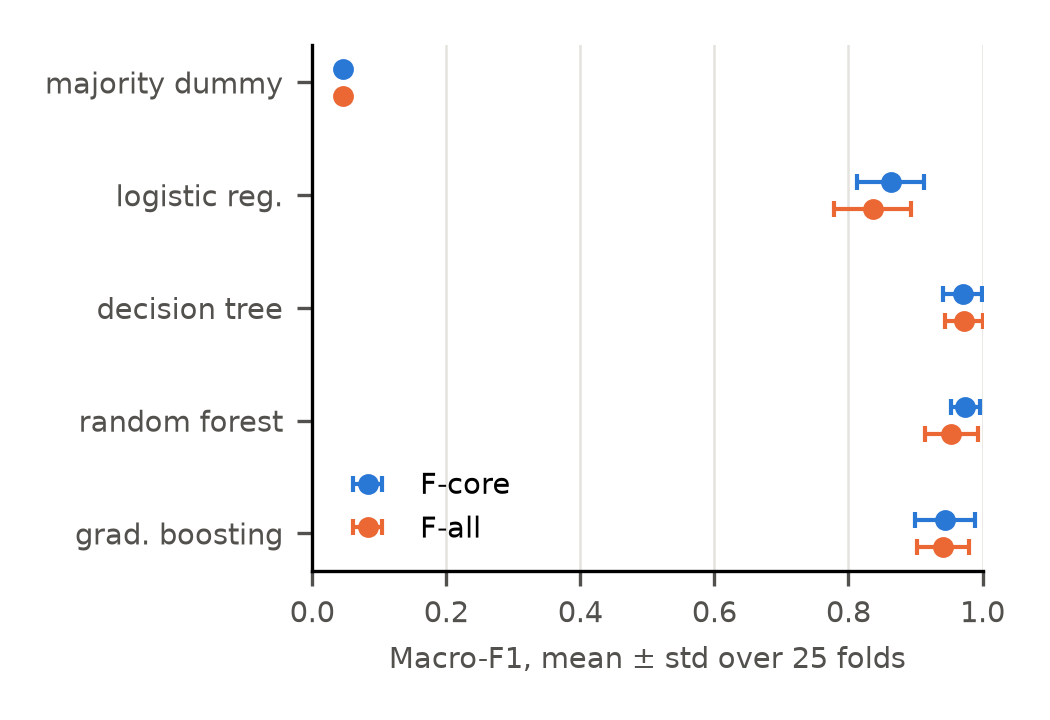

In [9]:
dev = load_dev(clean=True)
BANDS = {"HGB": [(12.5, 13.5)], "PLT": [(135, 165)], "WBC": [(9.5, 11.5)], "MCV": [(78, 82), (98, 102)],
         "MCHC": [(31.4, 32.5)]}
near = pd.Series(False, index=dev.index)
for c, bands in BANDS.items():
    for lo, hi in bands:
        near |= dev[c].between(lo, hi)
g = amend[(amend.fset == "F-core") & (amend.model == "tree") & (amend.imb == "weights")]
err, nn = (g["pred"] != g["y"]).to_numpy(), g["raw_row"].map(near).to_numpy()
near_rate, far_rate = 100 * err[nn].mean(), 100 * err[~nn].mean()
print(f"decision tree: error rate near a cut-off {near_rate:.1f}% against {far_rate:.1f}% elsewhere "
      f"({100 * near.mean():.1f}% of rows are near a cut-off)")
display(Markdown((P3 / "amended" / "main_results_table.md").read_text(encoding="utf-8")))
display(Image(filename=str(P3 / "amended" / "figures" / "fig_macro_f1_by_model.png"), width=520))

## 8. Did the re-run reproduce the committed results?

Without `RUN_FULL_CV` the evaluation reads the same predictions, so every rebuilt file must be identical to the snapshot. With `RUN_FULL_CV` on another computer, tiny floating-point differences are possible, so the summary tables are compared with a small tolerance. Then the numbers recomputed in this notebook are checked against the committed reports.

In [10]:
for rel, txt in SNAP.items():
    new = (P3 / rel).read_text(encoding="utf-8")
    if not RUN_FULL_CV:
        assert new == txt, f"{rel} changed"
    elif rel.endswith(".csv"):
        a = pd.read_csv(io.StringIO(txt), header=[0, 1], index_col=[0, 1, 2])
        b = pd.read_csv(io.StringIO(new), header=[0, 1], index_col=[0, 1, 2])
        print(rel, "largest difference after retraining:", float((a - b).abs().max().max()))
        assert float((a - b).abs().max().max()) < 0.005, rel

s_o = pd.read_csv(io.StringIO(SNAP["summary_metrics_cal.csv"]), header=[0, 1], index_col=[0, 1, 2])
s_a = pd.read_csv(io.StringIO(SNAP["amended/summary_metrics_cal.csv"]), header=[0, 1], index_col=[0, 1, 2])
tol = 6e-5 if not RUN_FULL_CV else 0.005
for _, row in tab.iterrows():
    key = ("F-core", row.model, row.arm)
    assert abs(row.orig_mean - s_o.loc[key, ("macro_f1", "mean")]) < tol, key
    assert abs(row.amend_mean - s_a.loc[key, ("macro_f1", "mean")]) < tol, key
saved_h2 = re.search(r"-> H2 model: (\w+) with (\w+)", SNAP["evaluation.txt"]).groups()
assert (h2_o, arm_o[h2_o]) == saved_h2 == (h2_a, arm_a[h2_a])
saved_t = float(re.search(r"forest\s+weights [\d.]+\s+smote [\d.]+.*?t = (-?[\d.]+)", SNAP["evaluation.txt"]).group(1))
assert round(res.t, 2) == saved_t
assert f"{probe1:.3f}" == re.search(r"probe1_fill_indicator: probe ([\d.]+)", SNAP["evaluation.txt"]).group(1)
saved_near = re.search(r"F-core\s+tree\s+error rate near ([\d.]+)% vs elsewhere ([\d.]+)%", SNAP["amended/evaluation.txt"]).groups()
assert (f"{near_rate:.1f}", f"{far_rate:.1f}") == saved_near
print("all checks passed: re-run reproduced the committed results, H2 =", saved_h2, ", t =", saved_t)

all checks passed: re-run reproduced the committed results, H2 =

 ('forest', 'smote') , t = -1.08


## 9. Questions for you (answer without looking)

1. What is nested cross-validation, and why does tuning happen only in the inner loop?
2. Why did calibration hurt logistic regression but not the random forest?
3. What does probe 2 of H4 show, and why does it matter even though F-core has no mean-filled columns?